<a href="https://colab.research.google.com/github/Drizello06/Quantum-Computing-Labs/blob/main/Lab_A_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Teleportation Protocol

In [1]:
%pip install 'iqm-client[qiskit]==35' --quiet
%pip install lagrangeclient --index-url https://gitlab.linksfoundation.com/api/v4/projects/1709/packages/pypi/simple

%pip install qiskit-aer==0.17

%pip install matplotlib pylatexenc # For visualization

from IPython.display import clear_output
clear_output()

In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, array_to_latex
from qiskit.result import marginal_distribution
from qiskit.circuit.library import UGate
from numpy import pi, random

Here is a quantum circuit implementation of the teleportation protocol.

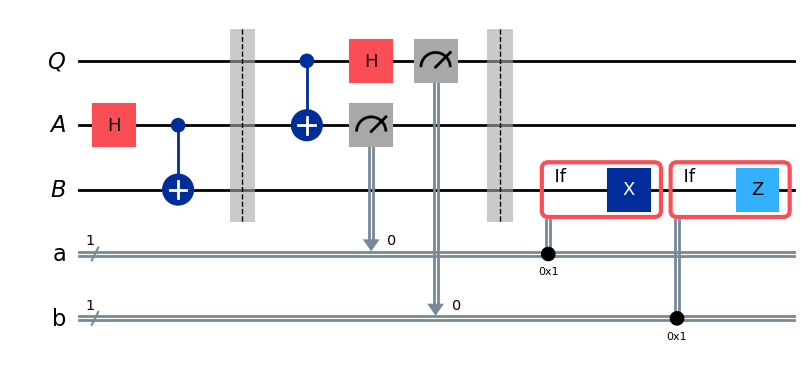

In [3]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

qubit = QuantumRegister(1, "Q")
ebit0 = QuantumRegister(1, "A")
ebit1 = QuantumRegister(1, "B")
a = ClassicalRegister(1, "a")
b = ClassicalRegister(1, "b")

protocol = QuantumCircuit(qubit, ebit0, ebit1, a, b)

# Prepare ebit used for teleportation
protocol.h(ebit0)
protocol.cx(ebit0, ebit1)
protocol.barrier()

# Alice's operations
#####################################

protocol.cx(qubit, ebit0)
protocol.h(qubit)

#####################################

# Alice measures and sends classical bits to Bob
protocol.measure(ebit0, a)
protocol.measure(qubit, b)
protocol.barrier()

# Bob applies corrections conditioned on the classical bits
with protocol.if_test((a, 1)):
    protocol.x(ebit1)
with protocol.if_test((b, 1)):
    protocol.z(ebit1)

display(protocol.draw(output="mpl"))

The *if_test* function applies an operation conditionally depending on a classical bit or register.

The circuit first initializes
$(A,B)$ to be in a $|\phi^+
\rangle$ state (which is not part of the protocol itself), followed by Alice's operations, then her measurements, and finally Bob's operations. To test that the protocol works correctly, we'll apply a randomly generated single-qubit gate to the initialized $|{0}\rangle$ state of $Q$ to obtain a random quantum state vector to be teleported. By applying the inverse (i.e., conjugate transpose) of that gate to $B$ after the protocol is run, we can verify that the state was teleported by measuring to see that it has returned to the $|{0}\rangle$ state.

First let's randomly choose a unitary qubit gate.

In [4]:
random_gate = UGate(
    theta=random.random() * 2 * pi,
    phi=random.random() * 2 * pi,
    lam=random.random() * 2 * pi
)

display(array_to_latex(random_gate.to_matrix()))

<IPython.core.display.Latex object>

Now we'll create a new testing circuit that first applies our random gate to $Q$, then runs the teleportation circuit, and finally applies the inverse of our random gate to the qubit $B$ and measures. The outcome should be $0$ with certainty.

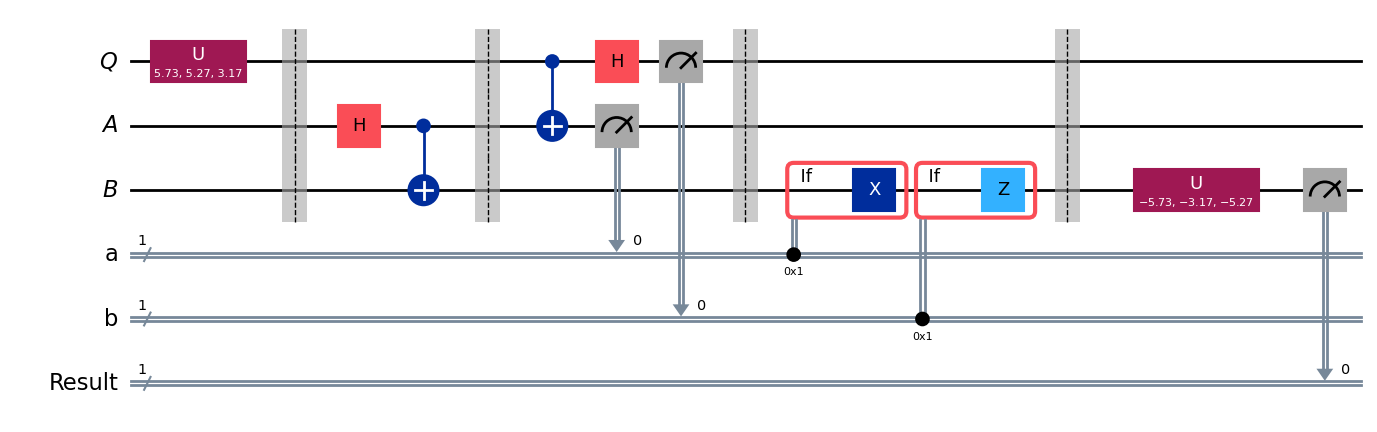

In [5]:
# Create a new circuit including the same bits and qubits used in the
# teleportation protocol.

teleportation_test = QuantumCircuit(qubit, ebit0, ebit1, a, b)

# Start with the randomly selected gate on Q

teleportation_test.append(random_gate, qubit)
teleportation_test.barrier()

# Append the entire teleportation protocol from above.

teleportation_test = teleportation_test.compose(protocol)
teleportation_test.barrier()

# Finally, apply the inverse of the random unitary to B and measure.

teleportation_test.append(random_gate.inverse(), ebit1)
result = ClassicalRegister(1, "Result")
teleportation_test.add_register(result)
teleportation_test.measure(ebit1, result)

display(teleportation_test.draw(output="mpl"))

Finally, let's run the Aer simulator on this circuit and plot a histogram of the outputs. We'll see the statistics for all three classical bits: the bottom/leftmost bit should always be $0$, indicating that the qubit $Q$ was successfully teleported into $B$, while the other two bits should be roughly uniform.

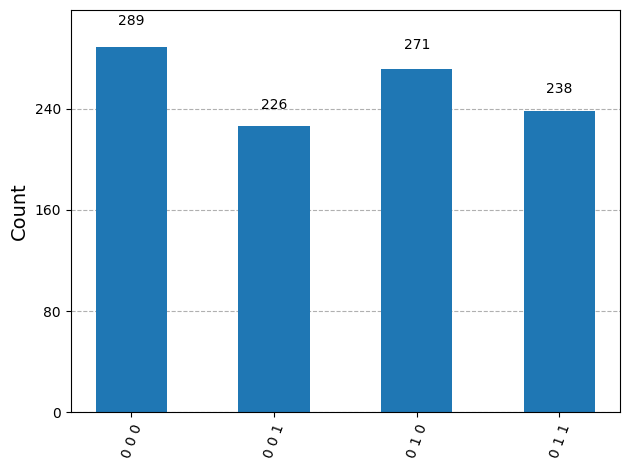

In [6]:
result = AerSimulator().run(teleportation_test).result()
statistics = result.get_counts()
display(plot_histogram(statistics))

We can also filter the statistics to focus just on the test result qubit if we wish, like this:

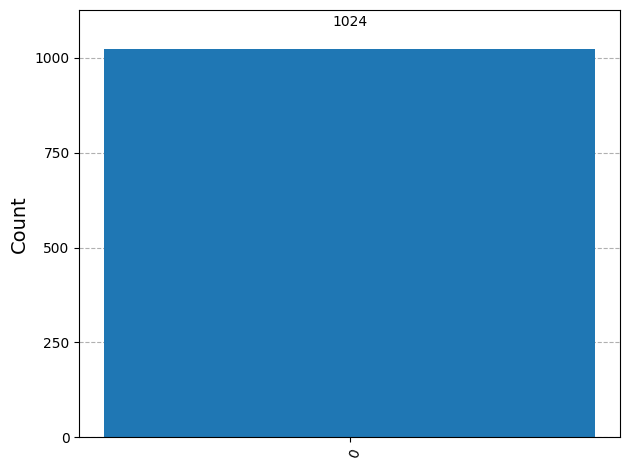

In [7]:
filtered_statistics = marginal_distribution(statistics, [2])
display(plot_histogram(filtered_statistics))

#  Superdense Coding Protocol

### Exercise 1: Complete the following code

let's use an additional qubit as a random bit generator — essentially to flip fair coins. We'll use it to randomly choose $c$ and $d$, and then run the superdense coding protocol.

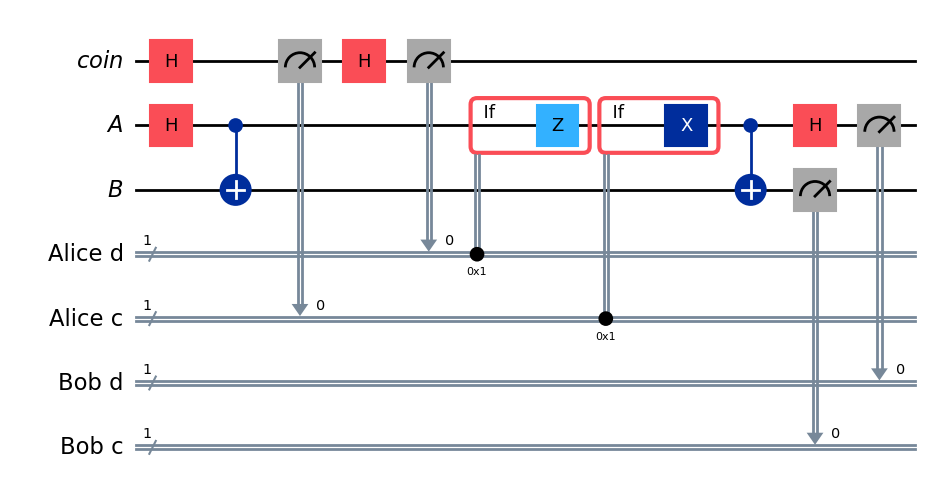

In [14]:
rbg = QuantumRegister(1, "coin")
ebit0 = QuantumRegister(1, "A")
ebit1 = QuantumRegister(1, "B")

Alice_c = ClassicalRegister(1, "Alice c")
Alice_d = ClassicalRegister(1, "Alice d")

test = QuantumCircuit(rbg, ebit0, ebit1, Alice_d, Alice_c)

# Initialize the ebit
##################################################################

test.h(ebit0)
test.cx(ebit0, ebit1)

##################################################################


# Use the 'coin' qubit twice to generate Alice's bits c and d. Then, the protocol runs,
# starting with Alice's actions, which depend on her bits.

##################################################################

test.h(rbg)
test.measure(rbg, Alice_c)
test.h(rbg)
test.measure(rbg, Alice_d)

with test.if_test((Alice_d, 1)):
    test.z(ebit0)
with test.if_test((Alice_c, 1)):
    test.x(ebit0)

##################################################################


# Bob's actions
##################################################################

test.cx(ebit0, ebit1)
test.h(ebit0)

##################################################################

Bob_c = ClassicalRegister(1, "Bob c")
Bob_d = ClassicalRegister(1, "Bob d")
test.add_register(Bob_d)
test.add_register(Bob_c)
test.measure(ebit0, Bob_d)
test.measure(ebit1, Bob_c)

display(test.draw(output="mpl"))

Running the Aer simulator shows the results: Alice and Bob's classical bits always agree.

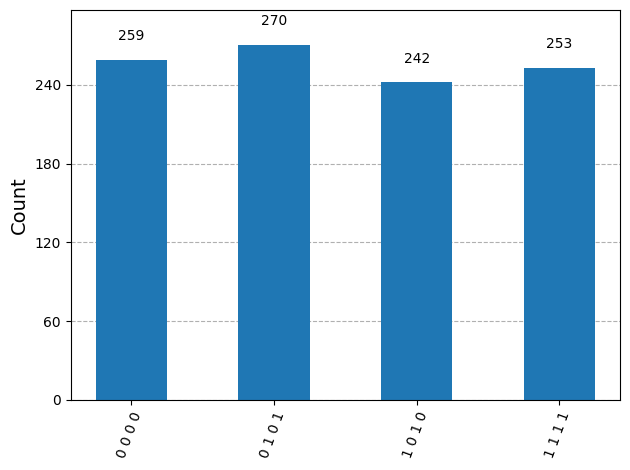

In [15]:
result = AerSimulator().run(test).result()
statistics = result.get_counts()
display(plot_histogram(statistics))

# Tests with real hardware

Let's get our token

In [16]:
!lagrangeclient

## On Windows
# import sys
# !{sys.executable} -m lagrangeclient

import json
with open('tokens.json', 'r') as f:
    config = json.load(f)
access_token = config['access_token']

== DEVICE LOGIN FLOW ==
🔗 Visit this URL in your browser:
https://spark.quantum.linksfoundation.com/auth/realms/cortex/device?user_code=OSZW-CRGH
Waiting for user to complete login...
=========== TOKEN ===========
eyJhbGciOiJSUzI1NiIsInR5cCIgOiAiSldUIiwia2lkIiA6ICJPN2g5cUtOOGRsdi1OZlo3Qm10NEJNZC0yaUFnMWt5STFEa2h0R3M5OU5rIn0.eyJleHAiOjE3OTI2ODYwMTMsImlhdCI6MTc5MjA4MTIxMywiYXV0aF90aW1lIjoxNzkyMDc1MDE2LCJqdGkiOiJvbnJ0ZGc6ZmE2NWJjZDUtOTQ0Ni1kMmZhLTM1NDktNDUyMWE3ZjFmMzVlIiwiaXNzIjoiaHR0cHM6Ly9zcGFyay5xdWFudHVtLmxpbmtzZm91bmRhdGlvbi5jb20vYXV0aC9yZWFsbXMvY29ydGV4IiwiYXVkIjoiYWNjb3VudCIsInN1YiI6IjAwYTAyZjdiLTljYjUtNDBlMi1hODJlLWE4ZjNjMGMyNGZlZSIsInR5cCI6IkJlYXJlciIsImF6cCI6ImlxbV9jbGllbnQiLCJzaWQiOiJlZmZkZThkMi02OGMzLTQ0YjUtOWRlMy04MDM2NjlhMzZjMjIiLCJhY3IiOiIwIiwiYWxsb3dlZC1vcmlnaW5zIjpbImh0dHBzOi8vc3BhcmsucXVhbnR1bS5saW5rc2ZvdW5kYXRpb24uY29tLyoiLCJodHRwczovL2Rhc2hib2FyZC5xdWFudHVtLmxpbmtzZm91bmRhdGlvbi5jb20iXSwicmVhbG1fYWNjZXNzIjp7InJvbGVzIjpbIm9mZmxpbmVfYWNjZXNzIiwidW1hX2F1dGhvcml6YXRpb24iLC

In [18]:
from iqm.qiskit_iqm import IQMProvider
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

provider = IQMProvider(url="https://spark.qtest.linksfoundation.com/", token=access_token)
lagrange_backend = provider.get_backend()

pm = generate_preset_pass_manager(optimization_level=1, backend=lagrange_backend)
transpiled_circuit = pm.run(teleportation_test)

job = lagrange_backend.run(transpiled_circuit, shots=1024)

ERROR:iqm.iqm_server_client.iqm_server_client:Job failed! Error(s):
  iqm-station-control: unknown: Playlist segment 0 can't be handled by the instruments and can't be broken to smaller parts. Violated limits:
- QB2__drive.awg unique feedback signal labels: 2/1


ValueError: need at least one array to concatenate

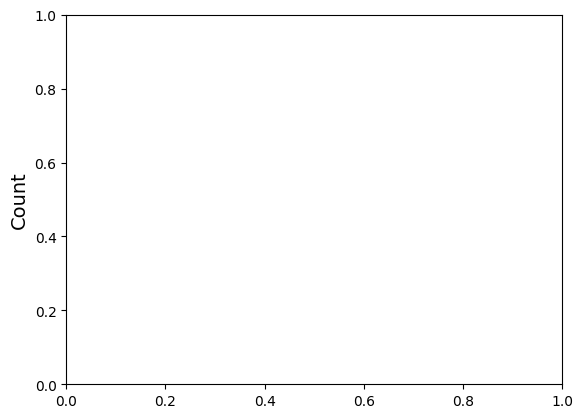

In [19]:
real_hw_statistics = job.result().get_counts()
display(plot_histogram(real_hw_statistics))

### Exercise 2: The Spark machine does not support Qiskit syntax for classically controlled quantum gates. What could be a workaround for this problem?

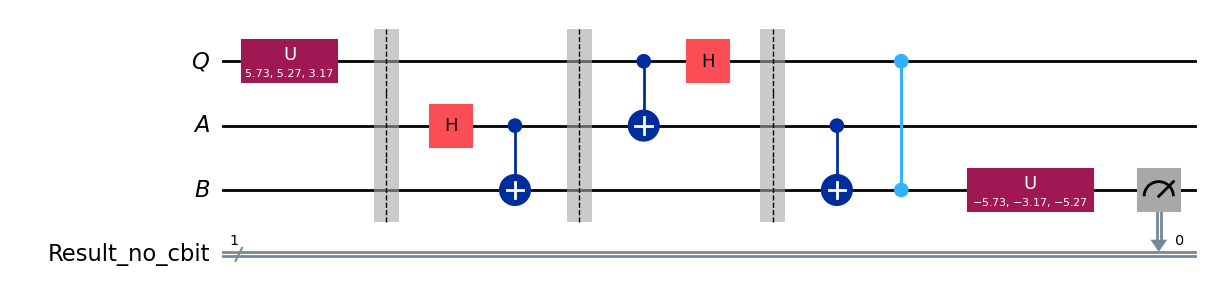

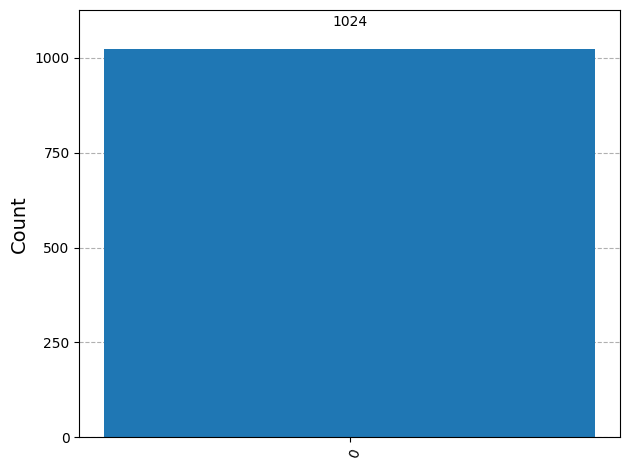

In [29]:
# Create a new circuit including the same bits and qubits used in the
# teleportation protocol.

qubit_no_cbit = QuantumRegister(1, "Q")
ebit0_no_cbit = QuantumRegister(1, "A")
ebit1_no_cbit = QuantumRegister(1, "B")

teleportation_test_no_cbit = QuantumCircuit(qubit_no_cbit, ebit0_no_cbit, ebit1_no_cbit)

# Start with the randomly selected gate on Q

teleportation_test_no_cbit.append(random_gate, qubit)
teleportation_test_no_cbit.barrier()

# Recreate the entire teleportation protocol from above.

#Entanglement
teleportation_test_no_cbit.h(ebit0_no_cbit)
teleportation_test_no_cbit.cx(ebit0_no_cbit, ebit1_no_cbit)

teleportation_test_no_cbit.barrier()

#Teleportation protocol
teleportation_test_no_cbit.cx(qubit_no_cbit, ebit0_no_cbit)
teleportation_test_no_cbit.h(qubit_no_cbit)

teleportation_test_no_cbit.barrier()

teleportation_test_no_cbit.cx(ebit0_no_cbit, ebit1_no_cbit)
teleportation_test_no_cbit.cz(qubit_no_cbit, ebit1_no_cbit)

# Finally, apply the inverse of the random unitary to B and measure.

teleportation_test_no_cbit.append(random_gate.inverse(), ebit1_no_cbit)
result_no_cbit = ClassicalRegister(1, "Result_no_cbit")
teleportation_test_no_cbit.add_register(result_no_cbit)
teleportation_test_no_cbit.measure(ebit1_no_cbit, result_no_cbit)

display(teleportation_test_no_cbit.draw(output="mpl"))

result = AerSimulator().run(teleportation_test_no_cbit).result()
statistics = result.get_counts()
display(plot_histogram(statistics))

### Exercise 3: Try to do the same to test the superdense coding protocol on the IQM Spark.

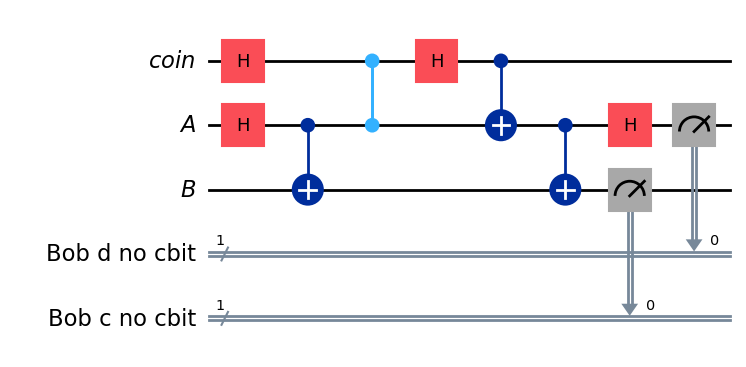

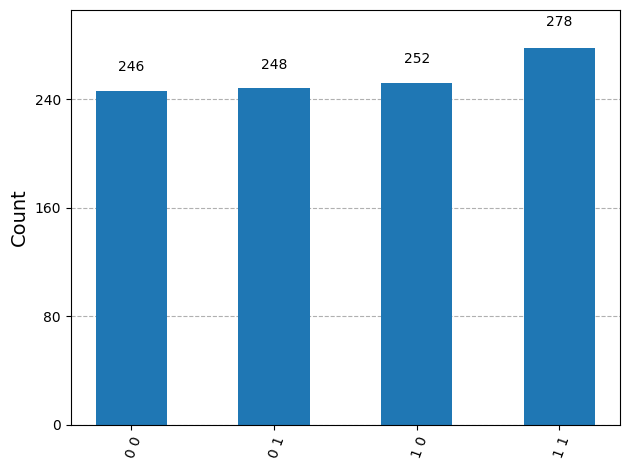

In [28]:
rbg_no_cbit = QuantumRegister(1, "coin")
ebit0_no_cbit = QuantumRegister(1, "A")
ebit1_no_cbit = QuantumRegister(1, "B")

test_no_cbit = QuantumCircuit(rbg_no_cbit, ebit0_no_cbit, ebit1_no_cbit)

# Initialize the ebit
##################################################################

test_no_cbit.h(ebit0_no_cbit)
test_no_cbit.cx(ebit0_no_cbit, ebit1_no_cbit)

##################################################################


# Use the 'coin' qubit twice to generate Alice's bits c and d. Then, the protocol runs,
# starting with Alice's actions, which depend on her bits.

##################################################################

test_no_cbit.h(rbg_no_cbit)
test_no_cbit.cz(rbg_no_cbit, ebit0_no_cbit)

test_no_cbit.h(rbg_no_cbit)
test_no_cbit.cx(rbg_no_cbit, ebit0_no_cbit)

##################################################################


# Bob's actions
##################################################################

test_no_cbit.cx(ebit0_no_cbit, ebit1_no_cbit)
test_no_cbit.h(ebit0_no_cbit)

##################################################################

Bob_c_no_cbit = ClassicalRegister(1, "Bob c no cbit")
Bob_d_no_cbit = ClassicalRegister(1, "Bob d no cbit")
test_no_cbit.add_register(Bob_d_no_cbit)
test_no_cbit.add_register(Bob_c_no_cbit)
test_no_cbit.measure(ebit0, Bob_d_no_cbit)
test_no_cbit.measure(ebit1, Bob_c_no_cbit)

display(test_no_cbit.draw(output="mpl"))

result = AerSimulator().run(test_no_cbit).result()
statistics = result.get_counts()
display(plot_histogram(statistics))